# P1-03. CNN 직접 만들기

**이 노트북의 목표**: 이미지 전용 구조인 **CNN(합성곱 신경망)**을 직접 만들어서, 노트북 2의 MLP와 비교하기.

**이 노트북에서 확인할 질문 3가지** (미리 예측해보고 시작하세요!)
1. MLP가 가장 헷갈려한 **glioma ↔ meningioma**가 CNN에서는 좋아질까?  
   → 예측: 이 둘은 *종양의 위치·모양*이 핵심인데, MLP는 위치 정보를 잃고 CNN은 유지하니까 좋아질 것
2. CNN은 파라미터가 MLP보다 **많을까 적을까?**
3. CNN이 실제로 이미지에서 **무엇을 보고** 있을까?

**노트북 2에서 달라진 점**

| 항목 | 노트북 2 (MLP) | 노트북 3 (CNN) | 왜 바꿨나 |
|---|---|---|---|
| 모델 | MLP (한 줄로 펼침) | CNN (2D 그대로) | 위치 정보 유지 |
| 해상도 | 64×64 | **128×128** | CNN은 해상도를 올려도 파라미터가 거의 안 늘어서 가능 |
| best 저장 기준 | val loss | **val macro F1** | 노트북 2에서 val loss 기준 best가 정확도엔 불리했음 |
| 학습 종료 | 30 epoch 고정 | **조기 종료(early stopping)** | 개선 없으면 자동으로 멈춰서 시간 절약 |

> 실행 후 **4-2(모양 추적), 7(학습 곡선), 8(test), 9(MLP 비교), 10(누수), 11(필터 시각화)** 출력을 Claude에게 보내주세요.

## 0. 준비

In [1]:
import random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             roc_auc_score, balanced_accuracy_score)

_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("사용 장치:", DEVICE)

d:\yerimlee\medimg-study\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


사용 장치: cuda:0


## 1. 데이터 준비 (노트북 2와 동일)

> 🎯 **왜 하나요?**  
> 노트북 2와 **똑같은 train/val/test**로 나눠야 MLP와 CNN을 공정하게 비교할 수 있어요.  
> 같은 `SEED=42`, 같은 `test_size=0.15`, 같은 `stratify`를 쓰면 정확히 같은 이미지가 같은 셋에 들어가요.  
> 바뀐 건 **해상도(128×128)** 하나뿐이에요.

In [2]:
DATA_ROOT = Path("../../data/raw").resolve()
OUT = Path("../../outputs/p1").resolve()

clean = pd.read_csv(OUT / "brain_index_clean.csv")
full  = pd.read_csv(OUT / "brain_index.csv")
for d in (clean, full):
    d["abs_path"] = d["path"].map(lambda p: str(DATA_ROOT / p))

CLASSES = sorted(clean["label"].unique())
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}

train_all = clean[clean["split"] == "train"]
test_df   = clean[clean["split"] == "test"].reset_index(drop=True)
train_df, val_df = train_test_split(train_all, test_size=0.15, stratify=train_all["label"], random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
print(f"train {len(train_df):,} / val {len(val_df):,} / test {len(test_df):,}  (노트북 2와 같은지 확인: 4,333 / 765 / 882)")

IMG_SIZE = 128

def load_gray(path, size=IMG_SIZE):
    with Image.open(path) as im:
        im = im.convert("L").resize((size, size), Image.BILINEAR)
    return np.asarray(im, dtype=np.float32) / 255.0

class BrainMRIDataset(Dataset):
    def __init__(self, df, mean=None, std=None, desc=""):
        self.labels = torch.tensor(df["label"].map(CLS2IDX).values, dtype=torch.long)
        imgs = [load_gray(p) for p in tqdm(df["abs_path"], desc=f"{desc} 로딩")]
        self.images = torch.from_numpy(np.stack(imgs)).unsqueeze(1)    # N×1×128×128
        self.mean, self.std = mean, std
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x = self.images[i]
        if self.mean is not None:
            x = (x - self.mean) / self.std
        return x, self.labels[i]

train_ds = BrainMRIDataset(train_df, desc="train")
MEAN, STD = train_ds.images.mean().item(), train_ds.images.std().item()
train_ds.mean, train_ds.std = MEAN, STD
val_ds  = BrainMRIDataset(val_df,  MEAN, STD, desc="val")
test_ds = BrainMRIDataset(test_df, MEAN, STD, desc="test")

train_loader = DataLoader(train_ds, batch_size=64,  shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=256, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)
print("한 장의 모양:", tuple(train_ds[0][0].shape))

train 4,333 / val 765 / test 882  (노트북 2와 같은지 확인: 4,333 / 765 / 882)


test 로딩: 100%|██████████| 882/882 [00:08<00:00, 103.14it/s]

한 장의 모양: (1, 128, 128)


## 2. 합성곱(Convolution) 직관 잡기

> 🎯 **왜 하나요?**  
> CNN 모델을 바로 만들기 전에, **"필터 하나가 이미지에 무슨 일을 하는지"**를 눈으로 먼저 봐요.  
> CNN은 이런 필터를 **수십~수백 개 스스로 학습**하는 모델이에요. 여기선 사람이 직접 만든 필터 3개로 감을 잡아요.

**합성곱이 하는 일**: 3×3짜리 작은 가중치 판(필터)을 이미지 위로 한 칸씩 미끄러뜨리면서,  
**그 자리의 9개 픽셀 × 필터 9개 숫자를 곱해서 더한 값**을 출력해요.

- MLP: 픽셀 4,096개를 **한꺼번에** 섞음 → "어느 픽셀이 어느 픽셀 옆인지" 모름
- CNN: **주변 9개 픽셀끼리만** 섞음 → 이웃 관계(모양, 경계)를 봄
- 같은 필터를 **이미지 전체에 재사용** → 위치가 달라도 같은 패턴을 찾음, 가중치도 9개뿐

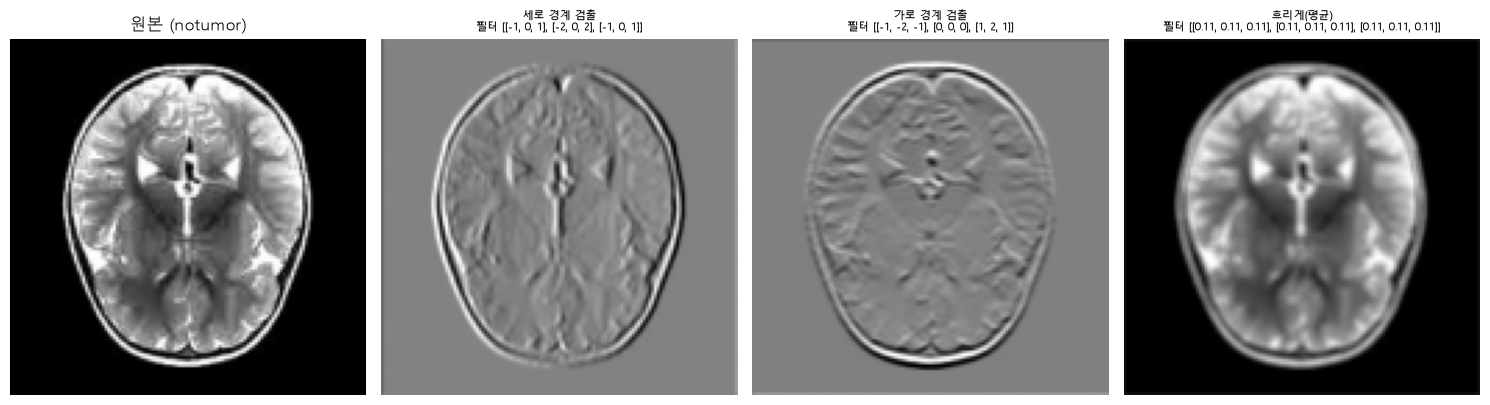

In [ ]:
x_demo, y_demo = train_ds[0]
x_demo = x_demo.unsqueeze(0)          # 1×1×128×128 (배치 축 추가)

# 필터 (=커널) 숫자를 어떻게 정하는지에 따라서 경계를 찾거나 흐리게 만들 수 있음 
# 128*128이라는 큰 사이즈에 3*3이라는 작은 필터를 쓰는 이유는 처음에는 작은 부분만 보는거 같지만 층을 쌓으면서 점점 큰 부분까지 같이 보게 되기 때문임 (대부분 3*3 사용)
filters = {
    "세로 경계 검출": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    "가로 경계 검출": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
    "흐리게(평균)":   [[1/9] * 3] * 3,
}

# 패딩을 두르지 않으면 데이터가 빨리 사라지게 되고, 데이터의 크기를 줄이는건 Pooling이 담당함. 그래서 데이터를 따로 줄이지 않고 크기를 그대로 유지하기로 함 
# 패딩을 사용하면 가장자리의 픽셀의 활용도가 떨어지게 되어 (계산에 포함되는 횟수가 중앙 대비 현저히 적은편) 이런 부분도 반영됨 
# 왜냐면, 우리 데이터에서 meningioma는 뇌 가장자리, 두개골쪽에 붙어있는 경우가 많은데, 가장자리 정보가 아예 없어지면 그 부분이 불리해짐 
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(x_demo[0, 0], cmap="gray"); axes[0].set_title(f"원본 ({CLASSES[y_demo]})")
for ax, (name, k) in zip(axes[1:], filters.items()):
    w = torch.tensor(k, dtype=torch.float32).view(1, 1, 3, 3)
    out = F.conv2d(x_demo, w, padding=1)          # padding=1: 가장자리에 0을 둘러서 크기 유지
    ax.imshow(out[0, 0], cmap="gray"); ax.set_title(f"{name}\n필터 {np.array(k).round(2).tolist()}", fontsize=8)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# 1개의 이미지에 3개의 필터를 적용했을때의 모습을 각각 보여주며, 뒤에 나오는 CNN에서는 하나의 이미지에 32,64,128,.. 등등 이보다 더 많은 필터를 적용해서 보게됨
# 필터 하나는 하나의 패턴만 찾을 수 있는데 종양 같은건 경계, 질감, 밝은 부분, 둥근 모양 등 여러 패턴이 동시에 필요해서 여러개의 필터를 사용함 

**풀링(Pooling)**: 2×2 칸마다 **가장 큰 값 하나만** 남겨서 크기를 반으로 줄여요.

> 🎯 **왜 줄이나요?**  
> 1. 계산량 감소  
> 2. 조금 위치가 어긋나도 같은 결과 → 종양이 몇 픽셀 옆에 있어도 같은 특징으로 인식 (분류에서는 장점이지만 검출, 분할에서는 단점임 --> Unet으로 커버)
> - 정확히 어디가 종양인지 짚어야하는데, 검출과 분할에서는 정확한 위치가 필요한데 풀링을 쓰면 데이터가 흐릿해지고 정확한 위치가 아닌 대략의 위치를 짚게되기 때문임
> - 현재 과제인 분류에서는 오히려 도움이 됨. 환자마다 종양 위치가 조금씩 다르고 같은 환자도 찍을때마다 머리 위치가 조금씩 다르기 때문에 몇 픽셀의 위치를 틀렸다고 다른 답을 내면 곤란해짐
> 3. 층을 지날수록 **한 픽셀이 보는 범위가 넓어짐** → 처음엔 작은 경계, 나중엔 큰 덩어리를 봄

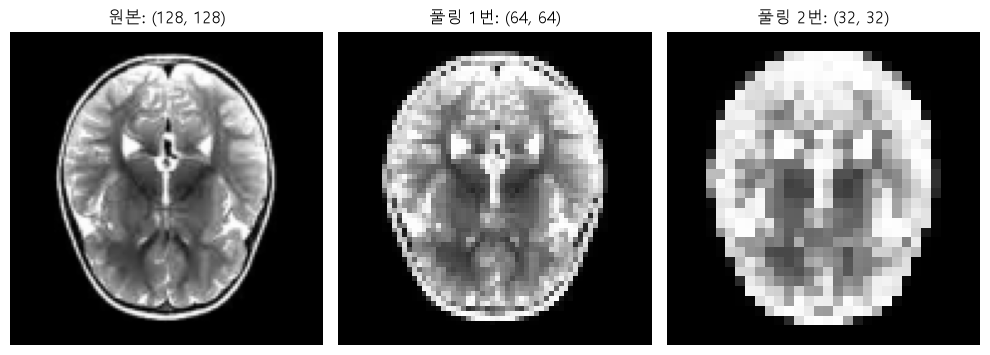

In [4]:
pooled = F.max_pool2d(x_demo, 2)
pooled2 = F.max_pool2d(pooled, 2)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, t, title in zip(axes, [x_demo, pooled, pooled2], ["원본", "풀링 1번", "풀링 2번"]):
    ax.imshow(t[0, 0], cmap="gray"); ax.set_title(f"{title}: {tuple(t.shape[-2:])}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. CNN 모델 정의

**구조**: `[Conv → BatchNorm → ReLU → MaxPool]` 블록을 4번 쌓고, 마지막에 분류기를 붙여요.

```
입력 1×128×128
 블록1: Conv(1→32)    → 32×128×128 → Pool → 32×64×64     작은 경계, 선
 블록2: Conv(32→64)   → 64×64×64   → Pool → 64×32×32     모서리, 질감
 블록3: Conv(64→128)  → 128×32×32  → Pool → 128×16×16   부분 모양
 블록4: Conv(128→256) → 256×16×16  → Pool → 256×8×8     큰 덩어리 (종양?)
 Global Average Pool  → 256        (채널마다 8×8 평균 → 숫자 1개)
 Dropout → Linear(256→4) → logit 4개
```

- **채널 수(32→64→128→256)** = 필터 개수 = "찾는 패턴의 종류 수". 노트북 2의 512, 128처럼 정답 없는 하이퍼파라미터
- 패딩의 수는 1로 고정되어있는데 3*3 필터에서는 1, 5*5에서는2, 7*7에서는 3을 사용함 
- 개수가 늘어날수록 조합할 수 있는 패턴 종류가 많아져서 찾을 패턴 수를 늘림 
- **크기는 줄고 채널은 늘어나는** 모양: 위치 정보는 압축하면서, 패턴 종류는 다양하게
- **BatchNorm**: 각 층 출력을 배치 단위로 평균 0, 표준편차 1로 다시 맞춰줌 → 학습이 안정적이고 빨라짐 (층마다 StandardScaler를 넣는 느낌)
- **Global Average Pool**: 8×8 지도를 평균 내서 숫자 하나로 → MLP처럼 픽셀을 펼치지 않아서 파라미터가 확 줄어듦

In [ ]:
# 하나의 블럭이 실행될때 아래의 함수들이 모두 실행됨 : 노말라이즈, 렐루, 맥스풀링 
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),   # BatchNorm이 절편 역할을 해서 bias 끔
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, n_classes=len(CLASSES)):
        super().__init__()
        self.block1 = conv_block(1, 32) # 입력 1채널, 필터 32개: 1개의 이미지를 넣으면 32개의 필터 시점에서 본 32개의 이미지가 나옴 
        self.block2 = conv_block(32, 64)# 입력 32채널, 필터 64개 
        self.block3 = conv_block(64, 128)
        self.block4 = conv_block(128, 256)
        self.pool = nn.AdaptiveAvgPool2d(1) # adaptive: 어떤 형태이든 출력이 1*1이 되도록 줄여줌 + AveragePooling 
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes)) # 1차원으로 변환한 후 dropout 적용 -> Linear로 256 -> 4로 
    def forward(self, x):
        x = self.block1(x); x = self.block2(x); x = self.block3(x); x = self.block4(x)
        return self.head(self.pool(x))

model = SimpleCNN().to(DEVICE)
n_cnn = sum(p.numel() for p in model.parameters())
print(f"CNN 파라미터 수: {n_cnn:,}개")
print(f"MLP 파라미터 수: 2,163,844개 (노트북 2, 그것도 64×64 입력)")
print(f"→ CNN이 약 {2163844 / n_cnn:.1f}배 적음. 해상도를 128로 올렸는데도!")

CNN 파라미터 수: 389,348개
MLP 파라미터 수: 2,163,844개 (노트북 2, 그것도 64×64 입력)
→ CNN이 약 5.6배 적음. 해상도를 128로 올렸는데도!


### 3-1. 데이터 모양이 층마다 어떻게 바뀌는지 추적

> 🎯 **왜 하나요?**  
> 노트북 2에서 shape(N×C×H×W) 읽는 법을 배웠죠. CNN은 층마다 **C는 늘고 H×W는 줄어드는** 게 핵심이라,  
> 실제로 그렇게 되는지 직접 찍어봐요. 나중에 모델을 직접 짤 때 shape 에러를 디버깅하는 연습이기도 해요.

In [6]:
model.eval()                                        # 확인만 할 거라 평가 모드
x = next(iter(train_loader))[0][:2].to(DEVICE)     # 2장만
print(f"입력        : {tuple(x.shape)}")
with torch.no_grad():
    for name in ["block1", "block2", "block3", "block4"]:
        x = getattr(model, name)(x); print(f"{name} 통과 후: {tuple(x.shape)}")
    x = model.pool(x);  print(f"전역 평균 풀링: {tuple(x.shape)}")
    x = model.head(x);  print(f"출력(logit)  : {tuple(x.shape)}  ← 2장 × 클래스 4개")

입력        : (2, 1, 128, 128)
block1 통과 후: (2, 32, 64, 64)
block2 통과 후: (2, 64, 32, 32)
block3 통과 후: (2, 128, 16, 16)
block4 통과 후: (2, 256, 8, 8)
전역 평균 풀링: (2, 256, 1, 1)
출력(logit)  : (2, 4)  ← 2장 × 클래스 4개


## 4. 학습 함수 (노트북 2와 거의 동일 — 템플릿 재사용)

> 🎯 **왜 거의 같나요?**  
> 노트북 2에서 말한 것처럼 **학습 루프 5단계는 모델이 바뀌어도 그대로**예요. MLP → CNN으로 바꿨는데 이 함수들은 한 글자도 안 바뀌어요.  
> 이게 PyTorch 구조의 장점이에요: **모델만 갈아끼우면 됨**.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, probs, ys = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        total_loss += criterion(out, y).item() * len(y)
        probs.append(torch.softmax(out, 1).cpu()); ys.append(y.cpu())
    probs, ys = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    pred = probs.argmax(1)
    return {"loss": total_loss / len(ys), "acc": (pred == ys).mean(),
            "macro_f1": f1_score(ys, pred, average="macro"), "probs": probs, "y": ys}

## 5. 학습 실행 (val macro F1 기준 best + 조기 종료)

> 🎯 **왜 기준을 바꿨나요?**  
> 노트북 2 누수 실험에서 **val loss로 고른 7 epoch 모델(0.870)보다 60 epoch 모델(0.922)이 더 잘했어요.**  
> loss는 "확신의 정도"까지 벌점을 줘서, 맞히는 개수가 늘어도 과신하면 나빠지거든요.  
> 우리 목적은 *분류를 잘하는 것*이라 **val macro F1이 가장 높을 때** 저장해요. (test가 아니라 **val로** 고르는 것 주의!)
>
> 🎯 **조기 종료(early stopping)는?**  
> val macro F1이 **`PATIENCE`번 연속 개선이 없으면 학습을 멈춰요.** 정체 구간을 계속 돌리는 시간 낭비를 막아요.

In [ ]:
EPOCHS, PATIENCE = 50, 10
CKPT = OUT / "p1_03_cnn_best.pt"
history, best_f1, wait = [], -1.0, 0

t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
    v = evaluate(model, val_loader)
    history.append({"epoch": ep, "train_loss": tr_loss, "val_loss": v["loss"],
                    "train_acc": tr_acc, "val_acc": v["acc"], "val_macro_f1": v["macro_f1"]})
    if v["macro_f1"] > best_f1: # 기준은 macro_f1 
        best_f1, wait, flag = v["macro_f1"], 0, "  ← best 저장"
        torch.save(model.state_dict(), CKPT)
    else:
        wait += 1; flag = f"  (개선 없음 {wait}/{PATIENCE})"
    print(f"[{ep:02d}] train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {v['loss']:.3f} acc {v['acc']:.3f} macroF1 {v['macro_f1']:.3f}{flag}")
    if wait >= PATIENCE:
        print(f"\n⏹ 조기 종료: {PATIENCE} epoch 연속 개선 없음"); break
print(f"학습 시간: {time.time() - t0:.0f}초 | best val macro F1: {best_f1:.3f}")
hist = pd.DataFrame(history)

[01] train loss 0.740 acc 0.707 | val loss 0.591 acc 0.775 macroF1 0.775  ← best 저장
[02] train loss 0.580 acc 0.780 | val loss 0.538 acc 0.771 macroF1 0.761  (개선 없음 1/10)
[03] train loss 0.507 acc 0.807 | val loss 0.510 acc 0.821 macroF1 0.824  ← best 저장
[04] train loss 0.436 acc 0.839 | val loss 0.535 acc 0.830 macroF1 0.830  ← best 저장
[05] train loss 0.413 acc 0.850 | val loss 0.516 acc 0.839 macroF1 0.835  ← best 저장
[06] train loss 0.376 acc 0.862 | val loss 1.234 acc 0.655 macroF1 0.584  (개선 없음 1/10)
[07] train loss 0.357 acc 0.872 | val loss 0.909 acc 0.646 macroF1 0.639  (개선 없음 2/10)
[08] train loss 0.345 acc 0.876 | val loss 0.552 acc 0.804 macroF1 0.804  (개선 없음 3/10)
[09] train loss 0.322 acc 0.880 | val loss 0.826 acc 0.664 macroF1 0.671  (개선 없음 4/10)
[10] train loss 0.297 acc 0.892 | val loss 0.367 acc 0.872 macroF1 0.878  ← best 저장
[11] train loss 0.263 acc 0.907 | val loss 0.390 acc 0.855 macroF1 0.857  (개선 없음 1/10)
[12] train loss 0.254 acc 0.908 | val loss 0.466 acc 0.834

## 6. 학습 곡선

> 🎯 **보는 법은 노트북 2와 같아요.** 이번엔 MLP 때와 비교해서  
> (1) val 성능이 얼마나 높은 곳까지 올라가는지, (2) train과 val의 간격(과적합)이 어떤지 봐주세요.

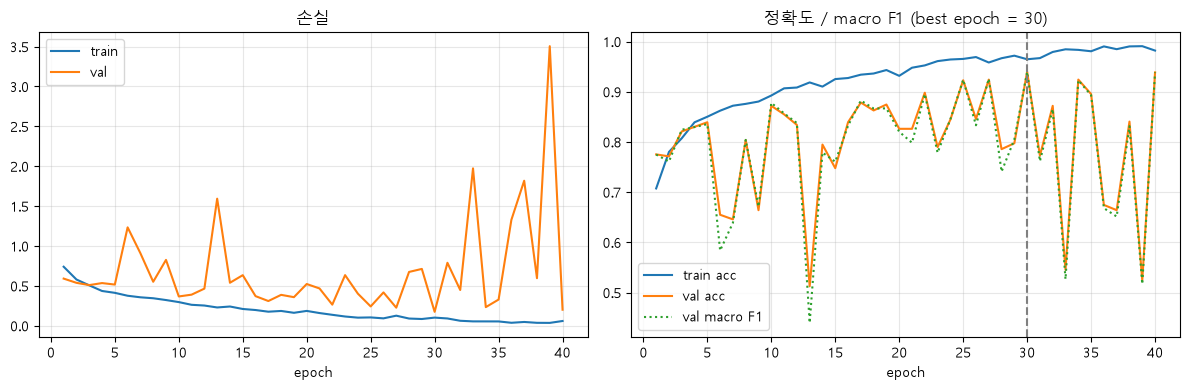

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train"); axes[0].plot(hist["epoch"], hist["val_loss"], label="val")
axes[0].set_title("손실"); axes[0].legend()
best_ep = hist.loc[hist["val_macro_f1"].idxmax(), "epoch"]
axes[1].plot(hist["epoch"], hist["train_acc"], label="train acc"); axes[1].plot(hist["epoch"], hist["val_acc"], label="val acc")
axes[1].plot(hist["epoch"], hist["val_macro_f1"], label="val macro F1", ls=":")
axes[1].axvline(best_ep, ls="--", c="gray"); axes[1].set_title(f"정확도 / macro F1 (best epoch = {best_ep})"); axes[1].legend()
for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# loss, f1이 너무 들쭉날쭉함 
# 가장 유력한 원인: 학습률 + BatchNorm 조합
# 학습률 0.001이 이 CNN에는 보폭이 큰 편이라, 가중치가 epoch마다 크게 흔들려요.
# BatchNorm은 학습할 때는 배치 64장의 평균으로 정규화하고, 평가할 때는 학습 중 누적해 둔 평균으로 정규화해요. 
# 가중치가 크게 흔들리면 이 누적 평균이 현재 가중치와 맞지 않게 되고, 평가 모드에서만 예측이 엉망이 될 수 있어요. train acc는 멀쩡한데 val만 튀는 패턴이 딱 이거예요.

## 7. Test 평가 (깨끗한 test, 딱 한 번)

Accuracy          : 0.955
Balanced accuracy : 0.959
Macro F1          : 0.957
Macro AUROC (OvR) : 0.994

              precision    recall  f1-score   support

      glioma      0.959     0.942     0.950       295
  meningioma      0.895     0.913     0.904       196
     notumor      0.990     1.000     0.995        97
   pituitary      0.980     0.980     0.980       294

    accuracy                          0.955       882
   macro avg      0.956     0.959     0.957       882
weighted avg      0.955     0.955     0.955       882



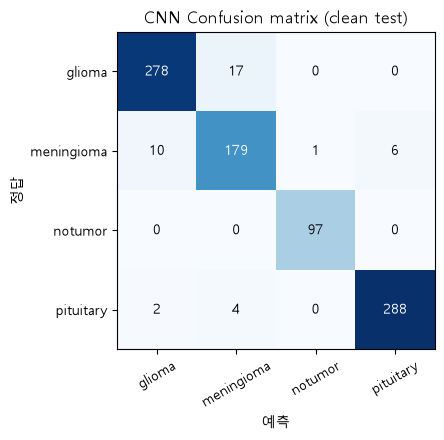

In [ ]:
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
r = evaluate(model, test_loader)
pred = r["probs"].argmax(1)
print(f"Accuracy          : {r['acc']:.3f}")
print(f"Balanced accuracy : {balanced_accuracy_score(r['y'], pred):.3f}")
print(f"Macro F1          : {r['macro_f1']:.3f}")
print(f"Macro AUROC (OvR) : {roc_auc_score(r['y'], r['probs'], multi_class='ovr'):.3f}\n")
print(classification_report(r["y"], pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(r["y"], pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30); ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("예측"); ax.set_ylabel("정답"); ax.set_title("CNN Confusion matrix (clean test)")
plt.tight_layout(); plt.show()

# 위의 그래프가 너무 들쭉날쭉해서 우연으로 인해 성능이 높게 나온건가 싶은데 balanced val macro f1이 0.939, test가 0.957으로 test가 val 보다 더 높게 나와서 성능 자체가 우연인건 아니고 30epoch 자체는 실력이 맞음 
# 다만, 30 에포크에서 멈췄으면 0.93인데 39에포크에서 멈췄으면 0.52였음. 동일 모델인데 언제 멈추는지에 따라서 성능이 극명하게 갈리는건 믿을수가 없음 
# notumor, pituitary는 1이거나 1에 근사한데 MLP에서 얘기했던 가설이 아직 남아있는거 같음 (사진의 방향등을 보고 구분하는것 )

## 8. MLP vs CNN 비교 ⭐

> 🎯 **왜 하나요?**  
> 노트북 시작할 때 세운 예측 **"CNN은 glioma ↔ meningioma를 더 잘 구분할 것"**을 확인해요.  
> MLP 숫자는 노트북 2에서 *사용자가 실제로 얻은 결과*를 그대로 적어뒀어요 (best 7ep 모델, clean test).  
> ※ 노트북 2를 다시 돌려서 숫자가 달라졌다면 아래 `MLP` 딕셔너리를 고쳐주세요.

In [11]:
MLP = {"acc": 0.870, "macro_f1": 0.870, "glioma": 0.827, "meningioma": 0.770, "notumor": 0.948, "pituitary": 0.952,
       "glioma→meningioma": 46, "meningioma→glioma": 30}

cnn_recall = {c: (pred[r["y"] == i] == i).mean() for i, c in enumerate(CLASSES)}
CNN = {"acc": r["acc"], "macro_f1": r["macro_f1"], **cnn_recall,
       "glioma→meningioma": int(cm[CLS2IDX["glioma"], CLS2IDX["meningioma"]]),
       "meningioma→glioma": int(cm[CLS2IDX["meningioma"], CLS2IDX["glioma"]])}

comp = pd.DataFrame({"MLP (64×64)": MLP, "CNN (128×128)": CNN})
comp["변화"] = comp["CNN (128×128)"] - comp["MLP (64×64)"]
comp.index = ["Accuracy", "Macro F1", "glioma 민감도", "meningioma 민감도", "notumor 민감도", "pituitary 민감도",
              "glioma→meningioma 오분류(장)", "meningioma→glioma 오분류(장)"]
comp.round(3)

,MLP (64×64),CNN (128×128),변화
Accuracy,0.870,0.955,0.085
Macro F1,0.870,0.957,0.087
glioma 민감도,0.827,0.942,0.115
meningioma 민감도,0.770,0.913,0.143
notumor 민감도,0.948,1.000,0.052
pituitary 민감도,0.952,0.980,0.028
glioma→meningioma 오분류(장),46.000,17.000,-29.000
meningioma→glioma 오분류(장),30.000,10.000,-20.000


## 9. 누수 실험 다시 (CNN)

> 🎯 **왜 또 하나요?**  
> 노트북 2에서 **"외우는 모델일수록 누수가 점수를 부풀린다"**를 확인했어요 (MLP 60ep: +1.3%p, meningioma +12.9%p).  
> CNN은 MLP보다 강한 모델이니까, **best 모델에서도 누수 효과가 보이는지** 확인해요.  
> 이건 노트북 4의 ResNet(더 강한 모델)으로 갈수록 노트북 1의 정리가 왜 더 중요해지는지 보여주는 근거예요.

In [ ]:
orig_test = full[full["split"] == "test"].reset_index(drop=True)
leak_only = orig_test[orig_test["test_leak"]].reset_index(drop=True)

rows = []
for name, d in [("① 깨끗한 test", test_df), ("② 원본 test", orig_test), ("③ 누수 이미지만", leak_only)]:
    ds = test_ds if d is test_df else BrainMRIDataset(d, MEAN, STD, desc=name)
    res = evaluate(model, DataLoader(ds, batch_size=256))
    by_cls = pd.Series(res["probs"].argmax(1) == res["y"]).groupby(d["label"].values).mean()
    rows.append({"평가셋": name, "장수": len(d), "acc": res["acc"], **by_cls.to_dict()})
pd.DataFrame(rows).set_index("평가셋").round(3)

# 누수이미지가 섞인 원본 test 보다 깨끗한 test 에서 성능이 더 좋음 --> 누수 이미지가 섞였을때 더 못맞춤 
# 이유1. train 을 외우지 않은 상태 (과적합이 아닌 상태)에서 val micro f1으로 best 를 고름
# 이유2. 누수 이미지 자체가 특이한 사진일 가능성: 노트북 예시에서 선명도를 바꾸거나, 반전하거나 구도를 바꾼 가공본이었어서 맞추기 어려웠을 수 있음 
# glioma는 2장이라 큰 의미 없음 

③ 누수 이미지만 로딩: 100%|██████████| 413/413 [00:00<00:00, 527.57it/s]


,장수,acc,glioma,meningioma,notumor,pituitary
평가셋,,,,,,
① 깨끗한 test,882,0.955,0.942,0.913,1.000,0.98
② 원본 test,1311,0.948,0.937,0.873,0.990,0.98
③ 누수 이미지만,413,0.935,0.500,0.806,0.986,1.00


## 10. CNN이 무엇을 보는지 엿보기

> 🎯 **왜 하나요?**  
> 2번에서는 *사람이 만든* 필터를 봤어요. 이번엔 **CNN이 학습으로 스스로 만든 필터**와,  
> 그 필터들이 이미지에서 **어디에 반응하는지(feature map)**를 봐요.  
> 블록이 깊어질수록 "선 → 모양 → 덩어리"로 바뀌는지 확인해보세요. 노트북 5의 Grad-CAM(모델이 판단 근거로 본 위치)의 예습이에요.

C:\Users\louis\AppData\Local\Temp\ipykernel_26388\3428855536.py:6: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.suptitle("블록1이 학습한 3×3 필터 32개 (빨강 = +, 파랑 = −)"); plt.tight_layout(); plt.show()
d:\yerimlee\medimg-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


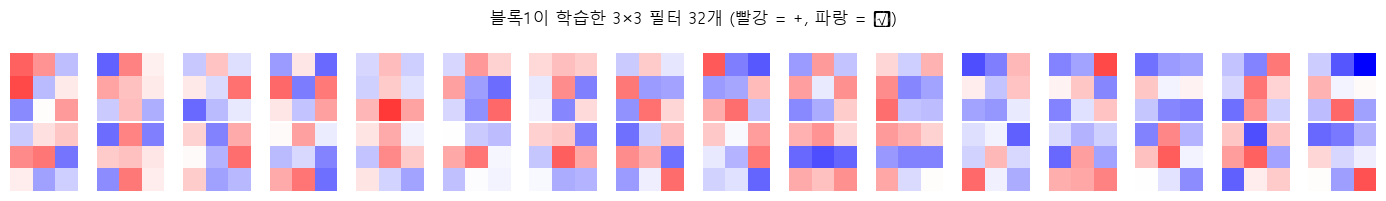

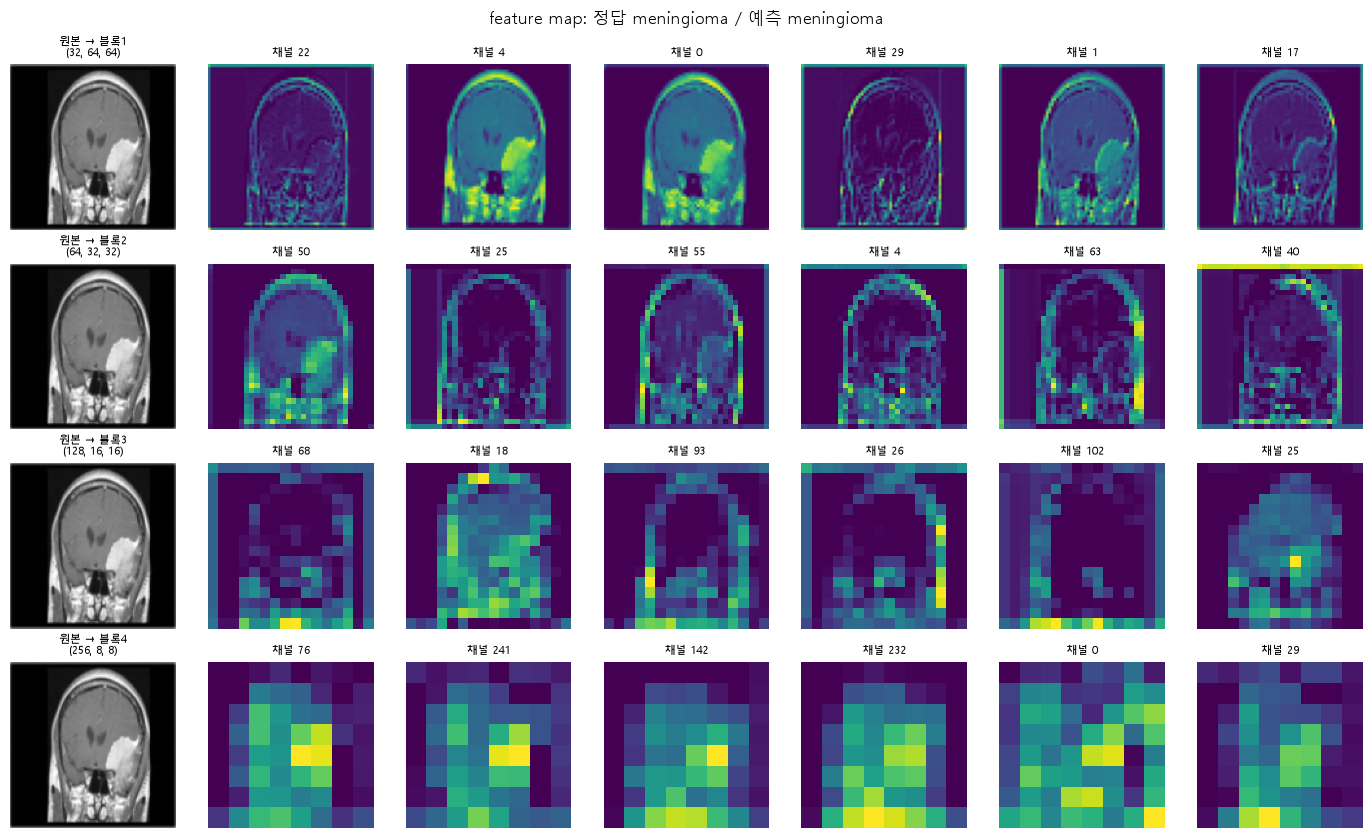

In [15]:
# (1) 첫 번째 층이 학습한 3×3 필터 32개
w = model.block1[0].weight.detach().cpu()[:, 0]          # 32×3×3
fig, axes = plt.subplots(2, 16, figsize=(14, 2))
for ax, k in zip(axes.ravel(), w):
    ax.imshow(k, cmap="bwr", vmin=-w.abs().max(), vmax=w.abs().max()); ax.axis("off")
plt.suptitle("블록1이 학습한 3×3 필터 32개 (빨강 = +, 파랑 = −)"); plt.tight_layout(); plt.show()

# (2) 한 장의 이미지가 블록을 지날 때 반응 지도 (각 블록에서 반응이 큰 채널 6개)
idx = int(np.where(r["y"] == CLS2IDX["meningioma"])[0][0])     # test에서 meningioma 한 장
x = test_ds[idx][0].unsqueeze(0).to(DEVICE)
model.eval(); maps = []
with torch.no_grad():
    h = x
    for name in ["block1", "block2", "block3", "block4"]:
        h = getattr(model, name)(h); maps.append(h[0].cpu())

fig, axes = plt.subplots(4, 7, figsize=(14, 8.5))
for row, (m, name) in enumerate(zip(maps, ["블록1", "블록2", "블록3", "블록4"])):
    axes[row, 0].imshow(x[0, 0].cpu(), cmap="gray"); axes[row, 0].set_title(f"원본 → {name}\n{tuple(m.shape)}", fontsize=8)
    top = m.mean((1, 2)).argsort(descending=True)[:6]
    for c, ch in enumerate(top):
        axes[row, c + 1].imshow(m[ch], cmap="viridis"); axes[row, c + 1].set_title(f"채널 {ch.item()}", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle(f"feature map: 정답 meningioma / 예측 {CLASSES[pred[idx]]}"); plt.tight_layout(); plt.show()

# 밝은 부분이 종양의 위치와 일치하기도 하지만, 이건 반응이 큰거지 이 근거로 판단했다는건 아님. 판단하고 싶으면 Grad-CAM을 통해서 확인이 필요함 
# 블록 4의 밝은 부분이 종양의 위치와 거의 일치함 --> 종양 덩어리에 반응해서 meningioma를 맞힌거임 --> meningioma, glioma의 혼동이 크게 줄어든 이유와도 비슷함 
# 필터 32개 중에서 1행 5열이나, 2행 8열은 한쪽이 빨갛고 다른 쪽이 파란 모양인데 2번셀의 경계 검출기와 비슷한 역할을 모델 스스로 한 것임

## 11. CNN 튜닝 및 Grad-CAM 그려보기

> 🎯 **왜 하나요?**  
> CNN 성능이 이상해서

[lr3e-4] 32 epoch에서 종료 | best val F1 0.928 | test acc 0.937, macro F1 0.937
[lr3e-4_cosine] 50 epoch에서 종료 | best val F1 0.955 | test acc 0.951, macro F1 0.955
총 125초


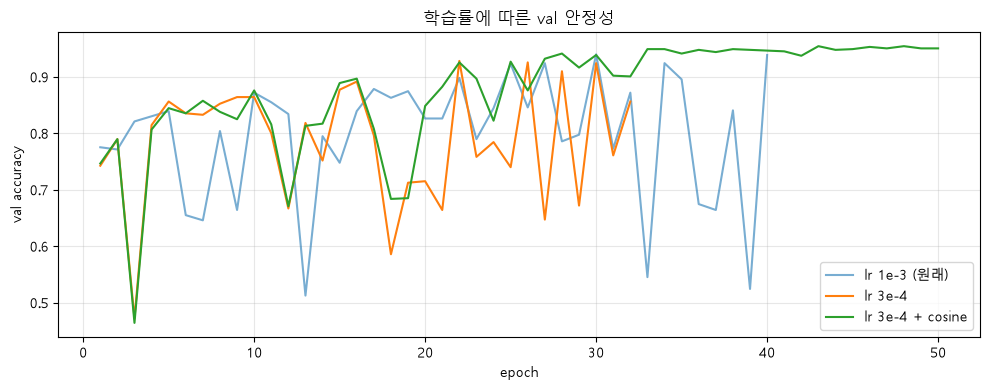

,lr 1e-3,lr 3e-4,lr 3e-4 + cosine
val acc 표준편차(10ep~),0.116,0.101,0.076
val acc 최저(10ep~),0.512,0.586,0.671
test acc,0.955,0.937,0.951
test macro F1,0.957,0.937,0.955


In [14]:
# 실험: 학습률 낮추기 (+ 스케줄러) → val이 안정되는가?
def run_experiment(lr, use_scheduler, tag, epochs=50, patience=10):
    torch.manual_seed(SEED)
    m = SimpleCNN().to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if use_scheduler else None
    ckpt = OUT / f"p1_03_cnn_{tag}.pt"
    hist_, best, wait = [], -1.0, 0
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(m, train_loader, opt)
        v = evaluate(m, val_loader)
        if sch: sch.step()
        hist_.append({"epoch": ep, "train_acc": tr_acc, "val_acc": v["acc"], "val_macro_f1": v["macro_f1"]})
        if v["macro_f1"] > best:
            best, wait = v["macro_f1"], 0; torch.save(m.state_dict(), ckpt)
        else:
            wait += 1
        if wait >= patience: break
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    t = evaluate(m, test_loader)
    h = pd.DataFrame(hist_)
    print(f"[{tag}] {len(h)} epoch에서 종료 | best val F1 {best:.3f} | test acc {t['acc']:.3f}, macro F1 {t['macro_f1']:.3f}")
    return h, t

t0 = time.time()
h_a, t_a = run_experiment(3e-4, False, "lr3e-4")
h_b, t_b = run_experiment(3e-4, True,  "lr3e-4_cosine")
print(f"총 {time.time() - t0:.0f}초")

# val 정확도 곡선 비교
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist["epoch"], hist["val_acc"], label="lr 1e-3 (원래)", alpha=.6)
ax.plot(h_a["epoch"], h_a["val_acc"], label="lr 3e-4")
ax.plot(h_b["epoch"], h_b["val_acc"], label="lr 3e-4 + cosine")
ax.set_xlabel("epoch"); ax.set_ylabel("val accuracy"); ax.set_title("학습률에 따른 val 안정성"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# 흔들림 정도 숫자로: 10 epoch 이후 val acc의 표준편차와 최저값
summary = pd.DataFrame({
    name: {"val acc 표준편차(10ep~)": h["val_acc"].iloc[9:].std(), "val acc 최저(10ep~)": h["val_acc"].iloc[9:].min(),
           "test acc": t["acc"], "test macro F1": t["macro_f1"]}
    for name, h, t in [("lr 1e-3", hist, r), ("lr 3e-4", h_a, t_a), ("lr 3e-4 + cosine", h_b, t_b)]
}).round(3)
summary

C:\Users\louis\AppData\Local\Temp\ipykernel_26388\26888985.py:34: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  plt.suptitle("Grad-CAM: 빨간 곳 = 모델이 그 예측을 할 때 중요하게 본 곳"); plt.tight_layout(); plt.show()
C:\Users\louis\AppData\Local\Temp\ipykernel_26388\26888985.py:34: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Malgun Gothic.
  plt.suptitle("Grad-CAM: 빨간 곳 = 모델이 그 예측을 할 때 중요하게 본 곳"); plt.tight_layout(); plt.show()
d:\yerimlee\medimg-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)
d:\yerimlee\medimg-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


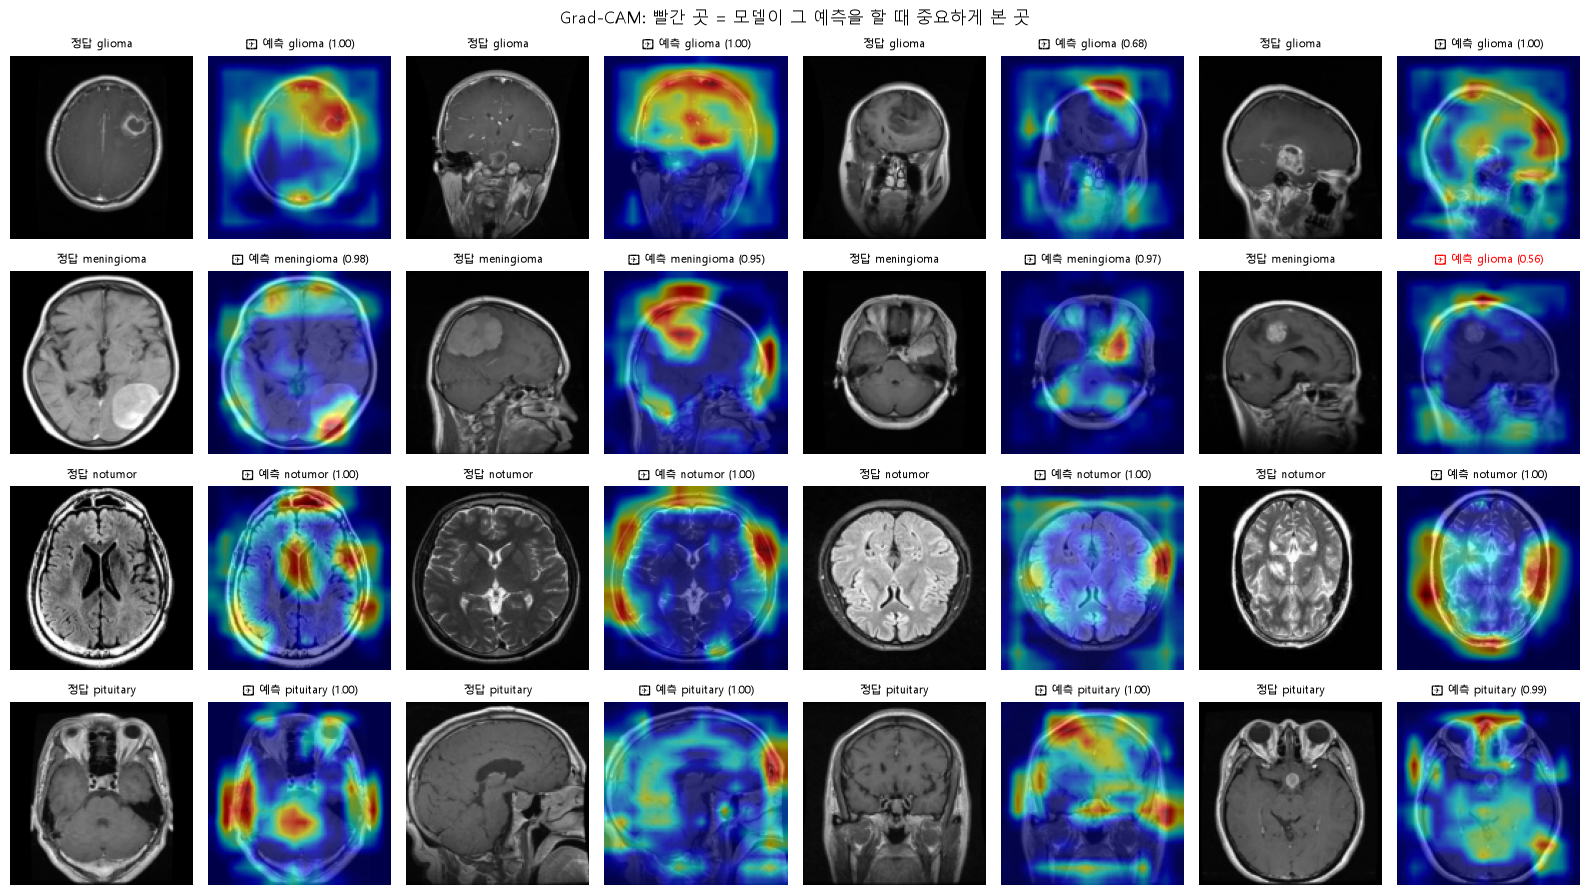

In [16]:
# Grad-CAM 미리보기: 모델이 판단할 때 어디를 봤나 (lr 3e-4 + cosine 모델)
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

cam_model = SimpleCNN().to(DEVICE)
cam_model.load_state_dict(torch.load(OUT / "p1_03_cnn_lr3e-4_cosine.pt", map_location=DEVICE))
cam_model.eval()

# 마지막 Conv 블록의 ReLU 출력(16×16)을 기준으로 계산
cam = GradCAM(model=cam_model, target_layers=[cam_model.block4[2]])

N = 4   # 클래스별 4장
fig, axes = plt.subplots(len(CLASSES), N * 2, figsize=(N * 4, len(CLASSES) * 2.3))
rng = np.random.default_rng(0)
for row, cls in enumerate(CLASSES):
    idxs = rng.choice(np.where(test_df["label"] == cls)[0], N, replace=False)
    for k, i in enumerate(idxs):
        x, y = test_ds[i]
        x = x.unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            p = torch.softmax(cam_model(x), 1)[0]
        pred = p.argmax().item()
        heat = cam(input_tensor=x, targets=None)[0]          # targets=None → 모델이 예측한 클래스 기준
        img = (x[0, 0].cpu() * STD + MEAN).clamp(0, 1).numpy()
        overlay = show_cam_on_image(np.stack([img] * 3, -1), heat, use_rgb=True)

        ax_o, ax_c = axes[row, k * 2], axes[row, k * 2 + 1]
        ax_o.imshow(img, cmap="gray"); ax_c.imshow(overlay)
        mark = "✓" if pred == y else "✗"
        ax_o.set_title(f"정답 {cls}", fontsize=8)
        ax_c.set_title(f"{mark} 예측 {CLASSES[pred]} ({p[pred]:.2f})", fontsize=8,
                       color="black" if pred == y else "red")
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Grad-CAM: 빨간 곳 = 모델이 그 예측을 할 때 중요하게 본 곳"); plt.tight_layout(); plt.show()

## 📝 메모: Grad-CAM 미리보기 — 모델은 어디를 보고 판단하는가?

### 1. 왜 했나
- CNN test 성능: Acc 0.955 / Macro F1 0.957 (MLP 0.870 대비 크게 향상)
- 그런데 클래스별 민감도가 **notumor 1.000, pituitary 0.980**으로 거의 완벽
- 노트북 1 EDA에서 발견한 클래스별 촬영 차이 때문에 **지름길(shortcut)로 맞힌 것 아닌가?** 의심
  - notumor: 뇌실이 하얀 **T2 영상**, 위에서 본 단면(axial) 위주 ↔ 종양 클래스는 T1 조영 영상
  - pituitary: **옆면(sagittal)·정면(coronal) 단면만**, 머리가 화면을 꽉 채운 확대 구도
- 특성맵(10번 셀)은 "채널이 어디에 반응했나"만 보여줌 → **"왜 이 클래스로 판단했나"**를 보려면 Grad-CAM 필요

### 2. 어떻게 했나
- 모델: `p1_03_cnn_lr3e-4_cosine.pt` (lr 3e-4 + cosine, 앞으로의 기본 설정)
- 기준 층: 마지막 Conv 블록(`block4`)의 ReLU 출력 → 16×16 지도를 128×128로 늘려서 원본에 겹침
- `targets=None` → **모델이 예측한 클래스** 기준으로 계산
- test에서 클래스별 랜덤 4장 (`np.random.default_rng(0)`)
- 읽는 법: **빨간색일수록** 그 예측에 중요하게 쓰인 영역 / 16×16 기반이라 **경계가 흐릿함** → 정확한 위치가 아니라 "이 근처" 정도로 해석

### 3. 클래스별 관찰

**glioma (4/4 정답) — 병변을 보기도 하지만 테두리에도 기댐**
- 1번 (axial): 오른쪽 위 **고리 모양 병변에 정확히 빨간색** → 이상적인 경우
- 2번, 3번 (coronal): 병변이 일반인 눈에 뚜렷하지 않음 → 판단 어려움. 3번은 확신도 0.68로 모델도 애매했음
- 4번 (sagittal): 가운데 병변보다 **두개골 테두리(오른쪽 위)가 가장 진함** → 종양이 아닌 곳에 집중

**meningioma (3/4 정답) — 병변을 보면 맞히고, 놓치면 틀림**
- 1번 (axial, 오른쪽 아래 큰 덩어리), 2번 (sagittal, 위쪽 둥근 덩어리): **종양 쪽이 빨감** ✓
- 3번 (axial, 두개저 높이): 가운데 오른쪽이 빨감 — 병변 위치는 육안으로 확인 어려움
- **4번 (sagittal, 위쪽 둥근 덩어리가 잘 보임): 종양을 거의 안 보고 glioma로 오답 (0.56)**
- → 종양 클래스끼리 구분할 때는 **병변을 근거로 쓰는** 것으로 보임 (못 보면 틀리니까)

**notumor (4/4 정답, 모두 1.00) — 거의 다 머리 테두리를 봄** ⚠️
- 1번: 가운데 뇌실 쪽이 빨감
- **2·3·4번: 머리 양옆 테두리(두개골·두피)가 빨갛고, 뇌 안쪽은 거의 파랑**
- → "종양이 없다"는 판단을 뇌 조직이 아니라 **머리 바깥 테두리**를 보고 내림
- 해석: notumor는 촬영 방식(T2 등)이 달라 **두개골·두피의 밝기·질감도 다르게 보임** → 그걸로 "notumor 스타일 사진"을 알아보는 지름길일 가능성 큼

**pituitary (4/4 정답, 0.99~1.00) — 종양을 거의 안 보는데 확신함** ⚠️⚠️
- 참고: 뇌하수체 위치 = **머리 한가운데, 눈 뒤쪽, 뇌 바로 아래** (콩알 크기)
- 1번 (axial): 가운데 빨간 점이 뇌하수체 근처 → 맞게 봤을 수도. 단, 양옆 테두리도 같이 빨감
- 2번 (sagittal), 3번 (coronal): 봐야 할 **가운데 아래쪽이 아니라 머리 뒤쪽·위쪽 테두리**를 봄
- **4번 (axial): 가운데 작고 동그란 밝은 점(종양으로 보임)이 있는데, 그 점이 아니라 위쪽(눈·이마)과 양옆 테두리를 보며 0.99 확신**
- 일부 사진은 종양이 해당 단면에 안 걸렸거나 128×128에서 뭉개져 안 보일 수도 있음
- → 종양을 안 보고도 확신 = **단면 방향(sagittal·coronal)이나 구도(확대)로 판단**하는 지름길 신호

### 4. 종합

| 클래스 | test 민감도 | Grad-CAM이 주로 본 곳 | 해석 |
|---|---|---|---|
| glioma | 0.942 | 병변 + 두개골 테두리 | 부분적으로 병변 사용 |
| meningioma | 0.913 | 병변 (놓치면 오답) | 병변 사용 ✓ |
| **notumor** | **1.000** | **머리 양옆 테두리** | 지름길 의심 강함 |
| **pituitary** | **0.980** | **테두리, 눈 쪽** (종양 보여도 안 봄) | 지름길 의심 강함 |

- **가장 잘 맞히는 두 클래스가 가장 엉뚱한 곳을 봄** → 노트북 1 EDA 가설(촬영 방식·단면 방향 차이 = 지름길)과 같은 방향
- 즉 **test 성능 95.5%가 "종양을 잘 본다"는 뜻은 아님**, 특히 notumor·pituitary는 사진 스타일로 맞혔을 가능성
- 반면 glioma ↔ meningioma 구분은 병변을 근거로 하는 편 → MLP 대비 CNN의 개선(오분류 76 → 27장)은 진짜 개선으로 볼 수 있음

### 5. 한계 (이 결과를 과신하지 말 것)
- **클래스당 4장**만 본 것 → 경향일 뿐, 결론 아님
- Grad-CAM은 16×16 기반이라 **위치가 흐릿함**
- 의학 전문가 판독이 아님 → "종양 위치"는 일반인 눈으로 본 추정
- 처음부터 학습한 작은 CNN 기준 → 사전학습 모델은 다르게 나올 수 있음

### 6. 다음에 할 것
- **노트북 4**: 사전학습 모델(ResNet 등) + **뇌 영역 기준 자르기**(여백·구도 차이 제거) + **증강**(뒤집기·회전·밝기) → 지름길이 줄어드는지, Grad-CAM이 바뀌는지 비교
- **노트북 5**: test 전체 대상으로 **"Grad-CAM 빨간 영역 중 테두리 비율"**을 클래스별로 숫자로 계산, 저해상도(16×16) 지름길 테스트, 확신하며 틀린 이미지(라벨 오류 후보) 확인
- 근본 한계: notumor(T2)·pituitary(sagittal·coronal만)처럼 **데이터 수집 방식 자체의 차이**는 모델링으로 완전히 없앨 수 없음 → 논문·포트폴리오에서는 한계로 명시, 외부 데이터 검증 필요

## ✍️ 정리 & 생각해볼 질문

1. 처음 세운 예측(glioma ↔ meningioma 개선)은 맞았나? 몇 장이나 줄었나?
2. CNN은 MLP보다 파라미터가 몇 배 적었나? 그런데 성능은? → 이게 의미하는 건?
3. notumor·pituitary도 더 좋아졌나, 아니면 이미 천장이었나? (지름길 가설과 연결)
4. 누수 실험에서 CNN best 모델의 ②−① 차이는 MLP best(+0.1%p)보다 컸나?
5. feature map에서 블록1과 블록4는 어떻게 달라 보였나?

**메모:**
- 
